In [12]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [13]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#BB7DC0',  # light purple
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          
plt.rcParams['axes.labelsize'] = 16     
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [14]:
graph_type = 'EA2D'
coup_type = 'ising'
d = 2
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    print(f"beta_uni = {beta_uni:.6f}")


beta_uni = 0.346574


In [15]:
if graph_type == 'ER' and coup_type in ('ising', 'gauss'):
    folder_data = f"perm/{graph_type}_{coup_type}"
else:
    folder_data = "tmp"
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/nb_star_DS_{graph_type}_{coup_type}_d{d}_N*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique(), "\nn_configs:", df['n_configs'].unique())
df

betas: [0.5  0.55 0.57 0.59 0.61] 
sizes: [100 300] 
n_configs: [2]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,time,mean_nb_star,std_nb_star,mean_nb_confs,std_nb_confs
0,0.50,F_beta_Glauber,False,2,50,100000000,100,50,1,4987.96,49.499075,1.0,0.0
1,0.50,F_beta_Glauber,False,2,50,100000000,100,50,2,4987.86,49.597988,1.0,0.0
2,0.50,F_beta_Glauber,False,2,50,100000000,100,50,3,4987.64,49.737616,1.0,0.0
3,0.50,F_beta_Glauber,False,2,50,100000000,100,50,4,4987.44,49.688695,1.0,0.0
4,0.50,F_beta_Glauber,False,2,50,100000000,100,50,5,4987.34,49.684851,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8365,0.61,F_beta_Glauber,False,2,50,100000000,300,0,92889787,10661.22,662.398167,1.0,0.0
8366,0.61,F_beta_Glauber,False,2,50,100000000,300,0,94618482,10681.52,687.307362,1.0,0.0
8367,0.61,F_beta_Glauber,False,2,50,100000000,300,0,96379348,10649.44,605.441365,1.0,0.0
8368,0.61,F_beta_Glauber,False,2,50,100000000,300,0,98172984,10692.30,605.925152,1.0,0.0


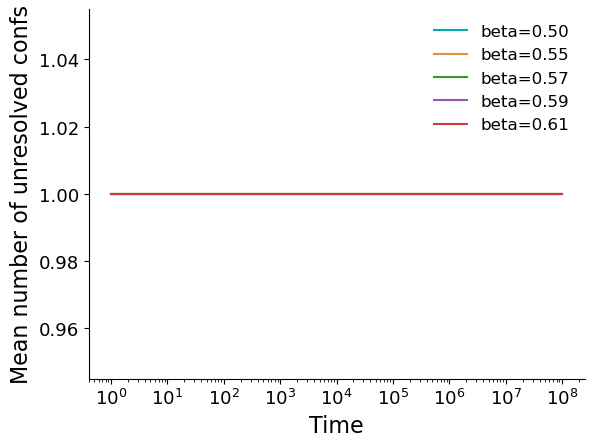

In [ ]:
if graph_type in ('EA2D', 'F2D'):
    N_plotted = 300
else:
    N_plotted = 10**5
    
mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_confs'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_confs'] - sub_df['std_nb_confs'],
                     sub_df['mean_nb_confs'] + sub_df['std_nb_confs'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of unresolved confs')
plt.legend()
plt.show()

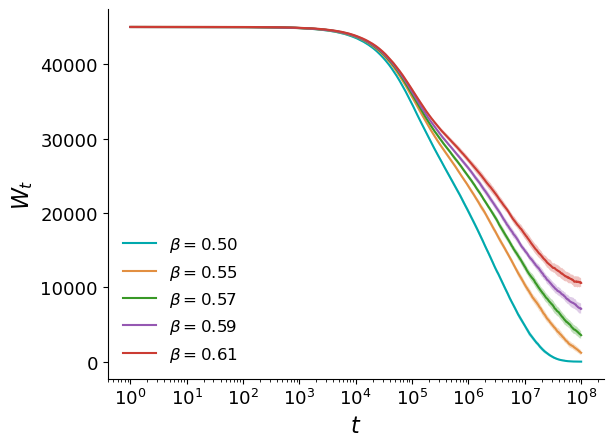

In [21]:
fig, ax = plt.subplots()

if graph_type in ('EA2D', 'F2D'):
    N_plotted = 300
else:
    N_plotted = 10**5

mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=rf'$\beta={beta:.2f}$')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel(rf'$t$')
plt.ylabel(rf'$W_t$')
plt.legend()
plt.show()

/tmp/ipykernel_15007/417122448.py:28: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
/tmp/ipykernel_15007/417122448.py:36: RuntimeWarning: divide by zero encountered in log
  log_W_shifted = np.log(sub_df['mean_nb_star'].values) - np.log(N)**2


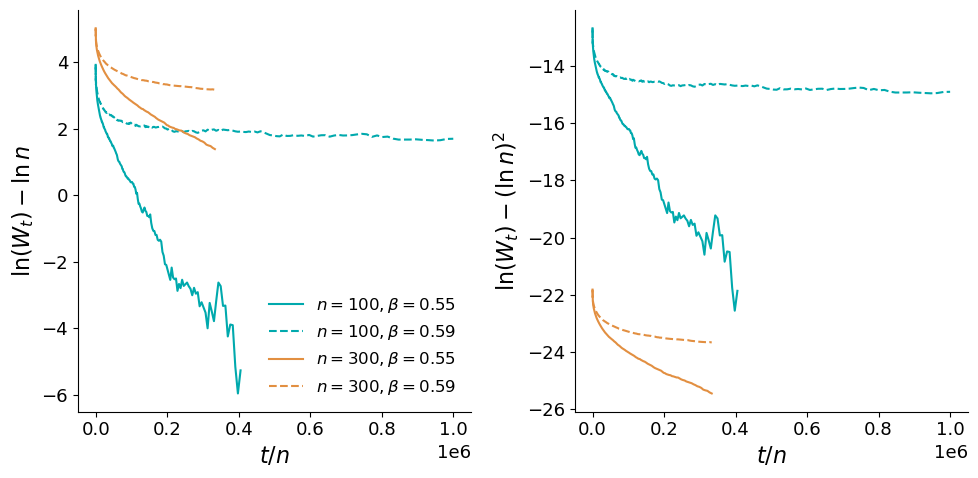

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

if graph_type == 'ER' and coup_type == 'ising':
    beta_list = [0.24, 0.25]
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_list = [0.30, 0.32]
else:
    beta_list = [0.55, 0.59] #df['beta'].unique()

if graph_type in ('EA2D', 'F2D'):
    N_list = [100, 300]
else:
    N_list = [10000, 100000]
t_over_min = 10
t_over_max = 500
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i, N in enumerate(N_list):
    color = prop_cycle[i % len(prop_cycle)]
    for beta in beta_list:
        csv_path = f"../results/{folder_data}/nb_star_DS_{graph_type}_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        linestyle = '-' if beta == beta_list[0] else '--'

        # --- test 1: n ln n scaling ---
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        axes[0].plot(t_over_N, log_W_over_N, color=color, linestyle=linestyle, label=rf'$n={N}, \beta={beta:.2f}$')
        mask = (t_over_N > t_over_min) & (t_over_N < t_over_max) & np.isfinite(log_W_over_N)
        if mask.sum() > 2:
            slope, intercept, r, _, _ = linregress(t_over_N[mask], log_W_over_N[mask])
            axes[0].plot(t_over_N[mask], intercept + slope * t_over_N[mask], ':', color=color, alpha=0.7)

        # --- test 2: n(ln n)^2 scaling ---
        log_W_shifted = np.log(sub_df['mean_nb_star'].values) - np.log(N)**2
        axes[1].plot(t_over_N, log_W_shifted, color=color, linestyle=linestyle, label=rf'$n={N}, \beta={beta:.2f}$')
        mask2 = (t_over_N > t_over_min) & (t_over_N < t_over_max) & np.isfinite(log_W_shifted)
        if mask2.sum() > 2:
            slope2, intercept2, r2, _, _ = linregress(t_over_N[mask2], log_W_shifted[mask2])
            axes[1].plot(t_over_N[mask2], intercept2 + slope2 * t_over_N[mask2], ':', color=color, alpha=0.7)

axes[0].set_xlabel(r'$t/n$')
axes[0].set_ylabel(r'$\ln(W_t) - \ln n$')
axes[0].legend()

axes[1].set_xlabel(r'$t/n$')
axes[1].set_ylabel(r'$\ln(W_t) - (\ln n)^2$')

plt.tight_layout()
plt.show()